# Validación y contrato común — Oslo, Proyecto 2

## 1. Alcance y entidades
Validar las salidas de 01–03 y fijar un contrato compartido para futuras estrategias de ubicación. Este notebook no implementa RANDOM, GREEDY, NSGA-II ni un nuevo simulador ecológico. Se distinguen validación de datos, pruebas de componentes y **validación ecológica pendiente**; ejecutar sin errores no demuestra que un modelo aún no calibrado reproduzca Oslo.

| Entidad | Definición y restricción |
|---|---|
| `FloralPatch` | Cualquiera de los 737 espacios verdes: recurso **potencial**, sin capacidad floral absoluta asignada. Una restricción para colmenas no elimina su posible recurso. |
| `CandidateHiveSite` | Punto derivado dentro de un espacio verde que supera el filtro conservador completo de zonas libres de abejas. Su validez es respecto de los datos/regla de esta versión; no se infieren permisos adicionales. |
| `Hive` | Colonia en uno de esos puntos. Cada ejecución futura tendrá exactamente K colonias en K sitios distintos. |

El horizonte común es diario, **2017-07-18 → 2017-08-04**, ambos extremos incluidos. Los meses y el año exploratorios de 03 no son recursos diarios calibrados. Se conserva la clasificación `observed`, `derived`, `modeled`, `scenario_parameter`. No se unen arbitrariamente traps sin coordenadas a los parques GIS.

In [1]:
%matplotlib inline
from pathlib import Path
import ast
import copy
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.ops import unary_union
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/bee_sim").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Ejecute desde el repositorio o un subdirectorio.")
sys.path.insert(0, str(ROOT / "src"))
from bee_sim.project2.contract import validate_hive_sites, event_rng, resource_step, bootstrap_ci, PROCESS_CODES
OUT = ROOT / "data/project2/processed"
START, END = pd.Timestamp("2017-07-18"), pd.Timestamp("2017-08-04")
YEAR = 2017
INPUTS = {name: OUT / name for name in ["spatial_patches.csv", "oslo_parks.geojson", "bee_free_zones.geojson",
                                     "simulation_calendar.csv", "temporal_variable_metadata.csv"]}
INPUTS.update({name: ROOT / "data/project2/raw/oslo" / name for name in
               ["floral_density_data_dryad_version.txt", "floral_visitation_data_dryad_version.txt"]})
for path in INPUTS.values():
    if not path.is_file():
        raise FileNotFoundError(f"Falta {path.relative_to(ROOT)}; ejecute primero 01–03.")
input_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in INPUTS.values()}
patches = pd.read_csv(INPUTS["spatial_patches.csv"])
parks = gpd.read_file(INPUTS["oslo_parks.geojson"])
zones = gpd.read_file(INPUTS["bee_free_zones.geojson"])
calendar = pd.read_csv(INPUTS["simulation_calendar.csv"], parse_dates=["date"])
metadata = pd.read_csv(INPUTS["temporal_variable_metadata.csv"])
report = []
def passed(check, details):
    report.append({"check": check, "status": "passed", "details": details})
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 120)
print("Entorno:", sys.version.split()[0], "| NumPy", np.__version__, "| pandas", pd.__version__, "| GeoPandas", gpd.__version__)
display(pd.DataFrame([{"input": name, "sha256": value} for name, value in input_hashes.items()]))

Entorno: 3.10.11 | NumPy 2.2.6 | pandas 2.3.3 | GeoPandas 1.1.4


,input,sha256
0,data\project2\processed\spatial_patches.csv,2145b59ed04aeee9e4611a7e81b6cf5afd6d94f757180af9490e0a378d45e757
1,data\project2\processed\oslo_parks.geojson,b1e37b09373c5b0e0cfca4c44ea7f8263c00d52648310e80c59dca560e9bd33d
2,data\project2\processed\bee_free_zones.geojson,1e020dbd81b2864bd4059466dfe2ea47e5bab5c4ec1f52a000992bdb062379b5
3,data\project2\processed\simulation_calendar.csv,267dc546d4c7317a521fa1fdb80ccea60fc1624a7a35f9f28f72206d4401f046
4,data\project2\processed\temporal_variable_metadata.csv,81d4be4b3a37f2da01d99943fd2c195f51d0d18835163bdf9e5df815dd5937ef
5,data\project2\raw\oslo\floral_density_data_dryad_version.txt,7750a3be81229e57a8052136e2a46f1599c5e1c33d654e9e050b82979039bd53
6,data\project2\raw\oslo\floral_visitation_data_dryad_version.txt,71813660a8ade147a46c4dbc42803be5f127b9e8611f300eac1374dd7da15bb1


## 2. Geometrías, IDs y separación entre recurso y colocación
Se inspeccionan las geometrías procesadas sin repararlas ni filtrarlas silenciosamente. El área métrica se compara con el CSV. Se recalcula la intersección con las zonas y se verifica el filtro de candidatura de 02.

Los centroides de un polígono cóncavo o multiparte pueden quedar fuera. Para esta primera matriz se define **un punto representativo interior por parque**, calculado en EPSG:25833; los candidatos usan ese mismo punto solo cuando el polígono completo es admisible. Es una aproximación geométrica, no una coordenada observada de colmena ni del centro floral. La regla de puntos se comparte entre todos los métodos.

Los polígonos de parques se solapan: no puede asignarse capacidad proporcional a su área y sumarse sin resolver el doble conteo. La política de recurso compartido en solapamientos queda pendiente antes de habilitar el motor.

In [2]:
assert parks.crs is not None and zones.crs is not None
for name, frame in [("parques", parks), ("zonas", zones)]:
    assert frame.geometry.notna().all() and not frame.geometry.is_empty.any()
    assert frame.geometry.is_valid.all() and frame.geom_type.isin(["Polygon", "MultiPolygon"]).all()
    passed(name + "_geometries", f"{len(frame)} geometrías válidas; CRS original {frame.crs}")
assert len(patches) == len(parks) == 737
assert patches.patch_id.notna().all() and patches.patch_id.is_unique and parks.patch_id.is_unique
assert set(patches.patch_id) == set(parks.patch_id)
parks = parks.set_index("patch_id").loc[patches.patch_id].reset_index().to_crs(25833)
zones = zones.to_crs(25833)
assert parks.crs.to_epsg() == zones.crs.to_epsg() == 25833
assert np.allclose(parks.geometry.area, patches.area_m2, rtol=1e-7, atol=.01)
restricted = unary_union(zones.geometry)
intersects = parks.geometry.intersects(restricted)
assert np.array_equal(intersects, patches.intersects_restricted_zone)
assert np.array_equal(~intersects, patches.is_initial_candidate)
points = parks.geometry.representative_point()
assert parks.geometry.covers(points).all()
reference_points = pd.DataFrame({"patch_id": patches.patch_id, "x_m": points.x, "y_m": points.y})
candidates = reference_points.loc[patches.is_initial_candidate].copy()
candidates.insert(0, "site_id", "site_" + candidates.patch_id)
candidates["crs"] = "EPSG:25833"
candidates["point_rule"] = "representative_point_of_wholly_unrestricted_polygon"
candidates = candidates.sort_values("site_id").reset_index(drop=True)
reference_points = reference_points.sort_values("patch_id").reset_index(drop=True)
assert len(candidates) == 375 and candidates.site_id.is_unique
candidate_geometry = gpd.GeoSeries(gpd.points_from_xy(candidates.x_m, candidates.y_m), crs=25833)
assert not candidate_geometry.intersects(restricted).any()
parent_geometries = parks.set_index("patch_id").loc[candidates.patch_id].geometry.reset_index(drop=True)
assert parent_geometries.covers(candidate_geometry).all()
passed("spatial_ids_and_candidates", f"737 parches; {len(candidates)} candidatos; 362 parches restringidos conservados como recurso potencial")
sum_area, union_area = parks.geometry.area.sum(), unary_union(parks.geometry).area
print("Área agregada:", sum_area / 1e6, "km² | unión:", union_area / 1e6, "km² | exceso por solapamiento:", (sum_area - union_area) / 1e6, "km²")
print("Centroides originales fuera del polígono:", int((~patches.centroid_inside_patch).sum()))
display(candidates.head())

Área agregada: 26.42224649123746 km² | unión: 23.56216130320754 km² | exceso por solapamiento: 2.860085188029919 km²
Centroides originales fuera del polígono: 165


,site_id,patch_id,x_m,y_m,crs,point_rule
0,site_patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_10,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_10,256600.799931,6.653545e+06,EPSG:25833,representative_point_of_wholly_unrestricted_polygon
1,site_patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_100,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_100,265242.514072,6.654082e+06,EPSG:25833,representative_point_of_wholly_unrestricted_polygon
2,site_patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_101,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_101,256640.091626,6.654458e+06,EPSG:25833,representative_point_of_wholly_unrestricted_polygon
3,site_patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_102,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_102,263754.205193,6.652142e+06,EPSG:25833,representative_point_of_wholly_unrestricted_polygon
4,site_patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_104,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_104,265973.696175,6.651198e+06,EPSG:25833,representative_point_of_wholly_unrestricted_polygon


## 3. Matriz sitio/parche de distancias
Matriz de 375 × 737 con distancia euclidiana **de ida** entre los puntos representativos en EPSG:25833. Incluye todos los parches como destinos, también los que no permiten colmenas. No son rutas, distancias entre bordes ni distancias reales de vuelo; los algoritmos usarán exactamente esta aproximación y el mismo orden de IDs. La distancia al parche de origen puede ser cero y debe admitirse en el motor futuro.

Se guarda `hive_patch_distances.npz` sin objetos pickle, con IDs, coordenadas, CRS y regla de distancia, y `candidate_hive_sites.csv` con los sitios válidos. No es todavía una selección de K colmenas.

patch_id,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_1,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_10,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_100,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_101,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_102
site_id,,,,,
site_patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_10,11724.937922,0.000000,8658.415294,914.123057,7289.543525
site_patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_100,9490.292541,8658.415294,0.000000,8610.625013,2444.932290
site_patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_101,12408.248654,914.123057,8610.625013,0.000000,7481.455207
site_patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_102,7512.297481,7289.543525,2444.932290,7481.455207,0.000000
site_patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_104,6778.724044,9662.325740,2975.948354,9886.703277,2412.284955


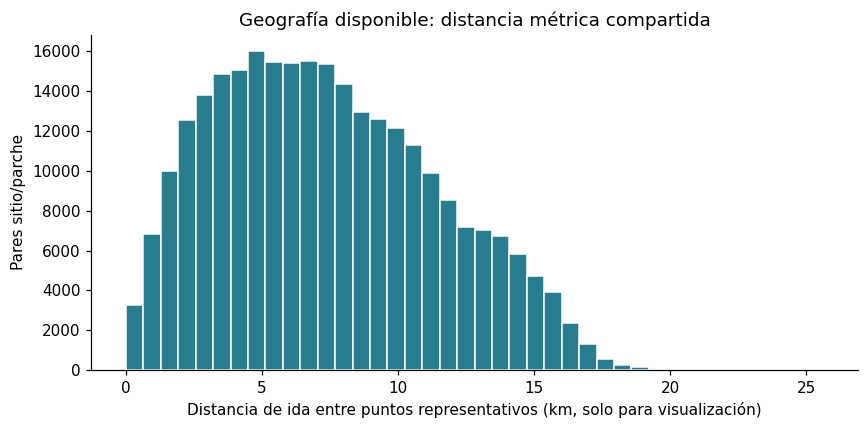

In [3]:
site_xy = candidates[["x_m", "y_m"]].to_numpy(dtype=float)
patch_xy = reference_points[["x_m", "y_m"]].to_numpy(dtype=float)
distances_m = np.linalg.norm(site_xy[:, None, :] - patch_xy[None, :, :], axis=2)
assert distances_m.shape == (len(candidates), len(reference_points))
assert np.isfinite(distances_m).all() and (distances_m >= 0).all()
patch_columns = {patch_id: i for i, patch_id in enumerate(reference_points.patch_id)}
assert all(distances_m[i, patch_columns[row.patch_id]] == 0 for i, row in candidates.iterrows())
passed("distances", f"{distances_m.size:,} distancias finitas y no negativas, en metros")
display(pd.DataFrame(distances_m[:5, :5], index=candidates.site_id.iloc[:5], columns=reference_points.patch_id.iloc[:5]))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(distances_m.ravel() / 1000, bins=40, color="#287D8E", edgecolor="white")
ax.set(xlabel="Distancia de ida entre puntos representativos (km, solo para visualización)", ylabel="Pares sitio/parche", title="Geografía disponible: distancia métrica compartida")
fig.tight_layout()
plt.show()

## 4. Calendario, evidencia y contraste con los archivos originales
Se verifica el calendario diario completo sin convertir días no muestreados en ceros. Las fechas florales sin año se contextualizan a 2017 según la documentación de 03; se vuelven a contar las 577 inferencias. Se reconstruyen dimensiones y densidad **por registro** con el mismo método, conservando duplicados potenciales y valores fraccionarios. Se cotejan fechas, conteos, traps, individuos y densidades con el calendario exportado.

Esto valida consistencia de datos/transformaciones, no capacidad floral, clima entre muestreos o parámetros de un simulador. La clasificación original permanece intacta: una fecha de calendario es derivada, un recurso futuro es modelado y un multiplicador es parámetro de escenario.

In [4]:
assert calendar.date.tolist() == pd.date_range(START, END, freq="D").tolist()
assert calendar.simulation_day.tolist() == list(range(1, 19))
assert calendar.date.is_unique and calendar.inside_calibrated_window.all()
assert calendar.primary_resolution.eq("daily").all() and not calendar.model_calibrated.any()
assert metadata.variable.is_unique
assert set(metadata.classification) == {"observed", "derived", "modeled", "scenario_parameter"}
assert set(calendar.columns).issubset(set(metadata.variable))
classes = metadata.set_index("variable").classification
assert classes["inventory_date"] == "observed" and classes["floral_density_mean"] == "derived"
assert classes["seasonal_floral_factor"] == "modeled" and classes["resource_multiplier"] == "scenario_parameter"

def load_dryad(path):
    for encoding in ("utf-8-sig", "cp1252"):
        try:
            return pd.read_csv(path, sep="\t", encoding=encoding, na_values=["NA", "N/A", ""])
        except UnicodeDecodeError:
            continue
    raise UnicodeError(f"No se pudo leer {path.name}")

def contextual_dates(series):
    text = series.astype("string").str.strip().str.lower()
    explicit = pd.to_datetime(text, format="%d.%m.%Y", errors="coerce")
    parts = text.str.extract(r"^(\d{1,2})\.(jul|aug)(?:\.(\d{2}|\d{4}))?$")
    month = parts[1].map({"jul": "07", "aug": "08"}).astype("string")
    written_year = parts[2].where(parts[2].str.len().eq(4), "20" + parts[2])
    explicit = explicit.fillna(pd.to_datetime(written_year + "-" + month + "-" + parts[0], format="%Y-%m-%d", errors="coerce"))
    context = pd.to_datetime("2017-" + month + "-" + parts[0], format="%Y-%m-%d", errors="coerce")
    inferred = explicit.isna() & parts[2].isna() & context.notna()
    return explicit.where(~inferred, context), inferred

flora = load_dryad(INPUTS["floral_density_data_dryad_version.txt"])
visits = load_dryad(INPUTS["floral_visitation_data_dryad_version.txt"])
flora["date"], flora["year_inferred"] = contextual_dates(flora.inventory_date)
visits["date"], visits["year_inferred"] = contextual_dates(visits.inventory_date)
assert flora.year_inferred.sum() == 577 and visits.date.isna().sum() == 1
assert (flora.date.min(), flora.date.max()) == (START, END)
assert visits.date.max() == pd.Timestamp("2017-08-10")
valid_area = flora.transect_width_cm.gt(0) & flora.transect_length_m.gt(0)
flora["density"] = flora.flower_number / (flora.transect_width_cm / 100 * flora.transect_length_m).where(valid_area)
visits["individuals_total"] = visits[["individuals_flying", "individuals_sitting"]].sum(axis=1, min_count=2)
fday = flora.groupby("date").agg(floral_records=("date", "size"), floral_traps=("trap_number", "nunique"),
    floral_density_mean=("density", "mean"), floral_density_median=("density", "median"),
    floral_year_inferred_records=("year_inferred", "sum"))
vday = visits.groupby("date").agg(visitation_records=("date", "size"), visitation_traps=("trap_number", "nunique"),
    visitation_individuals_total=("individuals_total", lambda s: s.sum(min_count=1)))
expected = fday.join(vday, how="outer").reindex(calendar.date)
for col in expected:
    assert np.allclose(calendar[col], expected[col], equal_nan=True), col
assert calendar.has_floral_observations.tolist() == calendar.date.isin(set(flora.date.dropna())).tolist()
assert calendar.has_visitation_observations.tolist() == calendar.date.isin(set(visits.date.dropna())).tolist()
assert calendar.loc[~calendar.has_floral_observations, ["floral_records", "floral_density_mean"]].isna().all().all()
passed("daily_calendar_and_Dryad", "18 días; 12 con inventario floral, 18 con visitas; conteos y densidad reconstruidos sin imputación")
passed("evidence_classification", "4 categorías presentes, coherentes con 03 y disponibles para todas las columnas del calendario")
display(calendar[["date", "floral_records", "floral_density_mean", "visitation_records", "visitation_individuals_total"]])

,date,floral_records,floral_density_mean,visitation_records,visitation_individuals_total
0,2017-07-18,17.0,8.847059,20,94
1,2017-07-19,39.0,1.855263,49,158
2,2017-07-20,NaN,NaN,123,352
3,2017-07-21,10.0,5.625000,61,171
4,2017-07-22,77.0,3.009064,97,307
5,2017-07-23,NaN,NaN,40,148
6,2017-07-24,33.0,2.839015,43,102
7,2017-07-25,55.0,2.184659,48,135
8,2017-07-26,108.0,2.252315,113,276
9,2017-07-27,51.0,2.384804,32,82


## 5. Estado del recurso e invariantes comprobables
Para cada parche j y día t, R_j(t) es el stock disponible al inicio del día, en una **unidad de recurso aún por definir y calibrar**, no flores/m², néctar en ml o polen por defecto.

`R_j(t+1) = max(0, R_j(t) - consumption_j(t) + regeneration_j(t))`

Convención común inicial: la regeneración del balance se acredita al cierre del día. Los consumos deben asignarse cronológicamente y de forma atómica contra un stock compartido por todas las colmenas; el consumo acumulado no puede superar R_j(t). El máximo con cero no permite ocultar sobreconsumo. Una pérdida durante el regreso no devuelve al parche lo ya consumido. La entrega a colonia y el retiro del recurso son registros distintos.

Se prueba la identidad con cantidades **sintéticas de test**, sin asignarlas a Oslo. No se ejecuta agotamiento/competencia ni se fijan capacidades absolutas; una validación de recursos no negativos durante una simulación completa queda pendiente de disponer del motor y parámetros.

In [5]:
assert np.array_equal(resource_step([0, 2, 10], [0, 1, 4], [1, 0, 2]), [1, 1, 8])
assert (resource_step([0, 2, 10], [0, 1, 4], [1, 0, 2]) >= 0).all()
for resource, consumption, regeneration in [([1], [2], [0]), ([1], [-1], [0]), ([np.nan], [0], [0])]:
    try:
        resource_step(resource, consumption, regeneration)
    except ValueError:
        pass
    else:
        raise AssertionError("Se aceptó un balance inválido")
passed("resource_balance_unit_invariant", "Balance y rechazo de sobreconsumo probados con fixtures; no simulan disponibilidad de Oslo")
# K=2 se usa solamente para probar el validador, no es el K del experimento.
fixture_sites = candidates.site_id.iloc[:2].tolist()
assert validate_hive_sites(fixture_sites[::-1], candidates.site_id, K=2) == tuple(sorted(fixture_sites))
for invalid, k in [([fixture_sites[0]] * 2, 2), (["invalid_site"], 1), (fixture_sites, 3)]:
    try:
        validate_hive_sites(invalid, candidates.site_id, k)
    except ValueError:
        pass
    else:
        raise AssertionError("Se aceptó una instalación inválida")
passed("K_valid_unique_sites", "Se rechazan IDs ajenos, duplicados y cantidades distintas de K; no se fijó K experimental")

## 6. Revisión del código de Proyecto 1
Se revisaron los archivos reales de `src/bee_sim/`. Reutilizar una distribución o una fórmula no implica reutilizar sus parámetros como calibración de Oslo. El motor actual representa una colonia/jornada y disponibilidad por viaje; no es ya un motor geográfico multi-colmena con recursos compartidos.

Se registran huellas y funciones de los archivos revisados para hacer comprobable el alcance de la evaluación. El código de Proyecto 1 no se modifica.

In [6]:
reuse_rows = [
    ("departures — simulation/departures.py", "partial", "Reutilizar generar_salidas A/B; fijar el mismo método para todos. Calibrar intensidad por colonia/día y jornada; tratar cierres y continuidad entre días."),
    ("distance — simulation/distance.py", "partial", "Sustituir sortear_distancia Weibull por matriz geográfica. Adaptar metros/km y velocidad. tiempo_vuelo usa 2D/V; permitir distancia cero; retorno logístico no calibrado."),
    ("flowers visited — simulation/flowers.py", "partial", "Reutilizar Poisson/negbin y validaciones; ligar media al recurso del parche y limitar consumo compartido. No adoptar niveles baja/media/alta sin ajuste."),
    ("pollination — simulation/pollination.py", "partial", "Reutilizar Bernoulli como hipótesis opcional; p_success sin evidencia aquí. Visitas Dryad no validan polinización efectiva."),
    ("nectar — simulation/nectar.py", "partial", "Reutilizar suma Gamma y dominios; no heredar escala/unidad ml como observada. Definir conversión y conservación con R; separar consumido y entregado."),
    ("trip duration — simulation/trip_duration.py", "partial", "Reutilizar suma vuelo+búsqueda+forrajeo; estimar escalas y velocidad, adaptar distancia métrica y jornadas. Duración de observación Dryad no es duración de un viaje."),
    ("return model — simulation/return_model.py", "partial", "Reutilizar chequeo horario y Bernoulli; recalibrar logística y transición de colonia entre días. No inferir supervivencia de visitas observadas."),
    ("random generators — generators/", "yes_with_adapter", "Reutilizar RNG explícito y transformaciones; PCG64 para CRN. LCG solo diagnóstico. Separar procesos/eventos: misma seed global no garantiza alineación bajo ramas diferentes.")]
reuse_assessment = pd.DataFrame(reuse_rows, columns=["component", "reusable", "changes_needed"])
display(reuse_assessment)
source_files = sorted((ROOT / "src/bee_sim/simulation").glob("*.py")) + sorted((ROOT / "src/bee_sim/generators").glob("*.py"))
source_audit = []
for path in source_files:
    content = path.read_text(encoding="utf-8-sig")
    functions = [node.name for node in ast.parse(content).body if isinstance(node, (ast.FunctionDef, ast.ClassDef))]
    source_audit.append({"file": str(path.relative_to(ROOT)), "functions/classes": ", ".join(functions),
                         "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
display(pd.DataFrame(source_audit))

,component,reusable,changes_needed
0,departures — simulation/departures.py,partial,Reutilizar generar_salidas A/B; fijar el mismo método para todos. Calibrar intensidad por colonia/día y jornada; tra...
1,distance — simulation/distance.py,partial,Sustituir sortear_distancia Weibull por matriz geográfica. Adaptar metros/km y velocidad. tiempo_vuelo usa 2D/V; per...
2,flowers visited — simulation/flowers.py,partial,Reutilizar Poisson/negbin y validaciones; ligar media al recurso del parche y limitar consumo compartido. No adoptar...
3,pollination — simulation/pollination.py,partial,Reutilizar Bernoulli como hipótesis opcional; p_success sin evidencia aquí. Visitas Dryad no validan polinización ef...
4,nectar — simulation/nectar.py,partial,Reutilizar suma Gamma y dominios; no heredar escala/unidad ml como observada. Definir conversión y conservación con ...
5,trip duration — simulation/trip_duration.py,partial,"Reutilizar suma vuelo+búsqueda+forrajeo; estimar escalas y velocidad, adaptar distancia métrica y jornadas. Duración..."
6,return model — simulation/return_model.py,partial,Reutilizar chequeo horario y Bernoulli; recalibrar logística y transición de colonia entre días. No inferir superviv...
7,random generators — generators/,yes_with_adapter,Reutilizar RNG explícito y transformaciones; PCG64 para CRN. LCG solo diagnóstico. Separar procesos/eventos: misma s...


,file,functions/classes,sha256
0,src\bee_sim\simulation\__init__.py,,af2299d2d21a773cb186364475e3945896eeda9a74087b0d7b198f2e5487f69c
1,src\bee_sim\simulation\departures.py,"metodo_a_interarribos, metodo_b_conteo, generar_salidas, generar_salidas_desde_config",ebf46c07125fa94eef8e0956a8644315a80b0c13658462e339344d5cdedf6fff
2,src\bee_sim\simulation\distance.py,"sortear_distancia, tiempo_vuelo, probabilidad_retorno",b802e7cf15b10fbdd7d5f805d97006a3af4fda94be99771abce10c6a77379c71
3,src\bee_sim\simulation\engine.py,"Jornada, simular_jornada",b8be93e11473dc3516ae64e65a8a6a4ca81b2ac7002728347f54020a8ae2d3df
4,src\bee_sim\simulation\flowers.py,"_modelo, sortear_flores, flores_del_viaje, momentos_teoricos",8d5959d38a5b4ad5fadee740bf3acb5eab0e402c69ddb07780657bb4f2dd06bf
5,src\bee_sim\simulation\metrics.py,"_exigir, _numero, verificar_invariantes, _cociente, resumir",d06c78af5d25d0d66717bfd493c38735e67107c3a5c13c6a7c52036ab88563f2
6,src\bee_sim\simulation\nectar.py,recolectar,79db45bcdbc8151ae0acacfc5dcb1b8df98407196877f2582940238deea6d648
7,src\bee_sim\simulation\pollination.py,"polinizar, tasa_observada, media_marginal_teorica",3b920409dc69260a44b9b99efdedd91dcf1a94fb35f6cf8915247d4bb60eb531
8,src\bee_sim\simulation\return_model.py,"_validar_numero, _probabilidad, cabe_en_jornada, sobrevive_distancia, retorna",d3aced392c917aca09632304b2df0476e9ef1e2a7c057af5e9399d1bb76db597
9,src\bee_sim\simulation\trip_duration.py,"_validar_tiempo, tiempo_busqueda, tiempo_forrajeo, duracion_total",4b332bf504914e39287c761e6b2f75fea437a2a82d8f8572700a864ea6e3d55a


## 7. Interfaz y flujo común futuro
Interfaz acordada: `simulate(hive_sites, seed, config)` → diccionario con `metrics`, `per_hive`, `trips`, `resource_log`, `provenance`. **Todavía no existe el motor espacial común**: este notebook define su contrato, sin devolver resultados ficticios.

- `hive_sites`: exactamente K `site_id` válidos, sin duplicados. Se ordenan canónicamente; `hive_slot` 0…K−1 identifica colonias para los flujos aleatorios. Permutar la misma entrada no cambia la simulación.
- `seed`: una seed de réplica del banco común, independiente de la seed interna del optimizador.
- `config`: misma versión del motor, inputs/huellas, K, fechas, unidades, distribuciones y parámetros para todos los métodos. Si faltan recursos, unidades o parámetros requeridos, el futuro motor debe rechazar la ejecución antes de consumir azar.
- `metrics`: las nueve claves del CSV contractual, aun cuando alguna sea indefinida y deba quedar ausente. Diagnósticos adicionales en otra sección, sin redefinir métricas por algoritmo.
- `per_hive`: K filas, incluidas colonias que entregaron cero; `hive_slot`, `site_id`, recurso entregado. `trips`: fecha, colonia, viaje, parche, distancia de ida, inicio/fin de forrajeo, consumo, entrega, retorno, competencia al seleccionar y competidores presentes al iniciar forrajeo.
- `resource_log`: parche/fecha, R inicial, consumo agregado, regeneración y R final; `provenance`: seed, config/input hashes, versiones y esquema de RNG.

Flujo diario: **inicio del día → generar viajes → seleccionar parche → viajar → forrajear → consumir recurso → regresar → registrar métricas**. El motor procesa los eventos de todas las colmenas en un reloj común, con orden de desempate fijo por tiempo, `hive_slot`, `trip_slot` y tipo de evento. Cerrar el balance diario y trasladar el estado antes del día siguiente. No ejecutar primero todas las extracciones de una colonia y luego las demás: sesgaría competencia y disponibilidad.

Los algoritmos posteriores solo proponen ubicaciones y llaman al mismo motor; no copian dinámica ni recalculan métricas con otra definición. Comparación de estrategias pendiente de validación; no se ejecuta ahora.

In [7]:
parameter_spec = pd.DataFrame([
    ("K", "scenario_parameter", "Exactamente K sitios; entero entre 1 y número de candidatos; valor pendiente del diseño experimental"),
    ("horizon / time_resolution", "scenario_parameter", "Fijos para comparación principal: 2017-07-18 a 2017-08-04, diaria"),
    ("resource_unit / initial_resources", "modeled", "Unidad y stock por parche sin cuantificar; no copiar ml de Proyecto 1 ni multiplicar áreas por Dryad sin correspondencia"),
    ("regeneration / overlap_policy", "modeled", "Sin parametrizar; renovación al cierre y tratamiento de áreas solapadas antes de asignar recursos"),
    ("alpha / beta / distance_scale_m", "scenario_parameter", "Pendientes de sensibilidad; alpha>=0, beta>=0 y escala de distancia>0"),
    ("departures / day_minutes / active_foragers", "modeled", "Familia, intensidad y esfuerzo diario/por colonia pendientes de calibración"),
    ("flowers / search / nectar / velocity", "modeled", "Familias reutilizables, parámetros y unidades por justificar; misma configuración para todos"),
    ("return / pollination / colony_transition", "modeled", "Probabilidades y continuidad de colonia entre días no identificadas con estos TXT"),
    ("seed bank / RNG schema / engine_version", "scenario_parameter", "Banco compartido, PCG64, claves de evento estables y versión congelada por comparación")],
    columns=["parameter", "classification", "requirement_or_pending_work"])
display(parameter_spec)

,parameter,classification,requirement_or_pending_work
0,K,scenario_parameter,Exactamente K sitios; entero entre 1 y número de candidatos; valor pendiente del diseño experimental
1,horizon / time_resolution,scenario_parameter,"Fijos para comparación principal: 2017-07-18 a 2017-08-04, diaria"
2,resource_unit / initial_resources,modeled,Unidad y stock por parche sin cuantificar; no copiar ml de Proyecto 1 ni multiplicar áreas por Dryad sin corresponde...
3,regeneration / overlap_policy,modeled,Sin parametrizar; renovación al cierre y tratamiento de áreas solapadas antes de asignar recursos
4,alpha / beta / distance_scale_m,scenario_parameter,"Pendientes de sensibilidad; alpha>=0, beta>=0 y escala de distancia>0"
5,departures / day_minutes / active_foragers,modeled,"Familia, intensidad y esfuerzo diario/por colonia pendientes de calibración"
6,flowers / search / nectar / velocity,modeled,"Familias reutilizables, parámetros y unidades por justificar; misma configuración para todos"
7,return / pollination / colony_transition,modeled,Probabilidades y continuidad de colonia entre días no identificadas con estos TXT
8,seed bank / RNG schema / engine_version,scenario_parameter,"Banco compartido, PCG64, claves de evento estables y versión congelada por comparación"


## 8. Selección de parche y competencia: hipótesis configurable
Para la colonia i en el instante de decisión, una forma conceptual es:

`score_j = R_j / ((1 + d_ij / distance_scale_m)**beta * (1 + alpha * competition_j))`

`P(j) = score_j / sum(score)`

La escala positiva convierte la distancia en una razón adimensional: no se suma 1 a una cantidad con unidades de metros. `alpha` y `beta` no se calibran ni se fijan aquí. `competition_j` será el número de **otras colonias distintas** con forrajeo activo en el parche al seleccionar el destino; la ocupación se registra para actualizar decisiones siguientes, sin medirla como densidad observada.

Solo se normalizan scores finitos, no negativos y de destinos accesibles con recurso identificado. Si la suma es cero, no hay elección/forrajeo disponible: registrar una oportunidad no atendida, sin pasar automáticamente a una uniforme. Los parches restringidos para colmenas siguen siendo destinos florales posibles. El registro de ocupación y asignación atómica de consumo requieren el futuro motor; no se implementan aquí.

## 9. Métricas comunes y denominadores
Una fila de métricas por **ejecución completa y seed**. RU es un símbolo de unidad de recurso pendiente de declarar en `config.resource_unit`, no una nueva medición ni conversión de flores a néctar.

Distancias: se adopta explícitamente la distancia euclidiana **de ida por viaje iniciado a un parche**, incluido un viaje sin retorno. La suma no se presenta como trayectoria real ni distancia total de vuelo ida/vuelta. El tiempo de vuelo puede usar 2D/V, con su propia convención explícita.

Sin viajes: distancia total y parches utilizados = 0; media/P95 y presión = ausentes. Sin recurso entregado: total/media/mínimo = 0 incluyendo todas las colonias, y equilibrio de Jain = ausente (0/0). No omitir claves ni eliminar colonias de bajo rendimiento. `direction` es preferencia de comparación, no un objetivo ya calibrado; presión y distancias no pueden optimizarse ignorando obtención de recurso.

In [8]:
metrics_contract = pd.DataFrame([
    ("total_resource_obtained", "Sum of resource delivered to all K colonies by successful returns within horizon; consumption on failed trips is not delivered", "RU: config.resource_unit, pending calibration", "maximize"),
    ("mean_resource_per_hive", "Total delivered / K, including zero-delivery colonies", "RU per hive", "maximize"),
    ("min_resource_per_hive", "Minimum cumulative delivered resource across exactly K colonies", "RU per hive", "maximize"),
    ("mean_distance_m", "Mean one-way point-to-point distance over initiated patch trips, including trips without return; undefined if none", "m", "minimize"),
    ("total_distance_m", "Sum of one-way distances over initiated patch trips; not round-trip or realized flight path; zero if no trips", "m", "minimize"),
    ("p95_distance_m", "95th percentile of same one-way trip distances using linear quantile; undefined if no trips", "m", "minimize"),
    ("competition_pressure", "Fraction of foraging attempts with at least one other distinct colony active in the patch at foraging start; undefined if no attempts", "fraction [0,1]", "minimize"),
    ("hive_balance_jain", "(sum delivered_i)^2 / (K * sum delivered_i^2); includes zero-delivery hives; undefined if all zero", "index [1/K,1] when defined", "maximize"),
    ("patches_used_count", "Distinct patch_id with positive resource consumption during horizon; zero if none", "count", "report_only")],
    columns=["metric", "definition", "unit", "direction"])
assert len(metrics_contract) == 9 and metrics_contract.metric.is_unique
display(metrics_contract)

,metric,definition,unit,direction
0,total_resource_obtained,Sum of resource delivered to all K colonies by successful returns within horizon; consumption on failed trips is not...,"RU: config.resource_unit, pending calibration",maximize
1,mean_resource_per_hive,"Total delivered / K, including zero-delivery colonies",RU per hive,maximize
2,min_resource_per_hive,Minimum cumulative delivered resource across exactly K colonies,RU per hive,maximize
3,mean_distance_m,"Mean one-way point-to-point distance over initiated patch trips, including trips without return; undefined if none",m,minimize
4,total_distance_m,Sum of one-way distances over initiated patch trips; not round-trip or realized flight path; zero if no trips,m,minimize
5,p95_distance_m,95th percentile of same one-way trip distances using linear quantile; undefined if no trips,m,minimize
6,competition_pressure,Fraction of foraging attempts with at least one other distinct colony active in the patch at foraging start; undefin...,"fraction [0,1]",minimize
7,hive_balance_jain,(sum delivered_i)^2 / (K * sum delivered_i^2); includes zero-delivery hives; undefined if all zero,"index [1/K,1] when defined",maximize
8,patches_used_count,Distinct patch_id with positive resource consumption during horizon; zero if none,count,report_only


## 10. Cien semillas comunes y CRN
Se generan 100 seeds uint32 de forma determinista desde `SeedSequence(2017)`. El 2017 del banco es una elección reproducible de diseño, no una estimación ecológica. Todos los métodos evaluarán las mismas réplicas bajo idéntico K, horizonte, parámetros y distribuciones. Sus generadores para buscar ubicaciones serán separados del banco de evaluación.

**Misma seed global no basta para Common Random Numbers** si cambian ramas, número de flores, rechazos Gamma o viajes fallidos. Se propone PCG64 con claves `(seed, day, hive_slot, trip_slot, draw_slot, process_code)`, códigos fijos y sin nombre de algoritmo ni `hash()` de Python. Cada evento/proceso tiene un bloque; los slots de oportunidades deben asignarse antes de las ramas y los sorteos por flor deben usar subslots estables. Repetir una clave reinicia el bloque, no crea azar independiente.

Se comprueba aislamiento entre procesos y reproducción de primitivas. La alineación efectiva de CRN entre configuraciones, el determinismo del futuro motor y su respuesta al orden de sitios son pruebas de aceptación **pendientes**; no se afirman a partir de un banco de seeds únicamente.

In [9]:
MASTER_SEED, N_SEEDS = 2017, 100
children = np.random.SeedSequence(MASTER_SEED).spawn(N_SEEDS)
seed_bank = pd.DataFrame({"replication_id": np.arange(1, N_SEEDS + 1),
                          "seed": [int(child.generate_state(1, dtype=np.uint32)[0]) for child in children]})
assert len(seed_bank) == 100 and seed_bank.seed.is_unique
assert seed_bank.seed.between(0, 2**32 - 1).all()
first_seed = int(seed_bank.seed.iloc[0])
expected = event_rng(first_seed, 0, 0, 0, "nectar").random(20)
event_rng(first_seed, 0, 0, 0, "flowers").random(1000)
assert np.array_equal(expected, event_rng(first_seed, 0, 0, 0, "nectar").random(20))
assert not np.array_equal(expected, event_rng(first_seed, 0, 0, 1, "nectar").random(20))
assert not np.array_equal(expected, event_rng(int(seed_bank.seed.iloc[1]), 0, 0, 0, "nectar").random(20))
passed("seeds_and_event_streams", "100 seeds únicas; primitivas deterministas; procesos separados; prueba de CRN del motor completo pendiente")
display(seed_bank.head(10))
display(pd.DataFrame(PROCESS_CODES.items(), columns=["process", "stable_code"]))

,replication_id,seed
0,1,3743917570
1,2,3728538546
2,3,2976030762
3,4,739891657
4,5,2053319738
5,6,980199163
6,7,2955027171
7,8,1570992533
8,9,2216227401
9,10,2344884574


,process,stable_code
0,departures,0
1,patch_selection,1
2,flowers,2
3,nectar,3
4,pollination,4
5,search,5
6,foraging,6
7,return,7
8,climate,8
9,regeneration,9


## 11. Reproducibilidad de componentes heredados e IC bootstrap
Prueba de humo: se ejecuta **el motor existente de Proyecto 1**, con una copia reducida y sintética de su configuración para limitar costo. Sus minutos, intensidad y tamaño de colonia son fixtures, no valores adoptados para Oslo. Se comprueba misma seed → mismos viajes/resultados del motor legado y sus invariantes; esto no valida el motor espacial futuro.

`bootstrap_ci` queda reutilizable en `bee_sim.project2.contract`. Usa IC percentil 95%, seed explícita y por defecto 5,000 remuestreos. La unidad de réplica son ejecuciones independientes; no se remuestrean viajes o días dependientes como si fueran réplicas. Para comparar estrategias con CRN se alinean por `(scenario, K, replication_id, seed)` y se remuestrean **diferencias emparejadas** de una métrica. Las muestras incompletas se revisan explícitamente: la función rechaza ausencias/no finitos. No se interpretan IC simultáneos o significancia causal de varios objetivos.

In [10]:
from bee_sim.config import cargar
from bee_sim.generators import crear_fuente
from bee_sim.simulation.engine import simular_jornada
from bee_sim.simulation.metrics import verificar_invariantes, resumir

fixture_config = copy.deepcopy(cargar(ROOT / "config/base.yaml"))
fixture_config["simulation"]["day_minutes"] = 10
fixture_config["departures"]["lambda_per_min"] = .2
fixture_config["colony"]["active_bees"] = 2
before_config = copy.deepcopy(fixture_config)
a = simular_jornada(fixture_config, crear_fuente("numpy", first_seed), run_id=0)
b = simular_jornada(fixture_config, crear_fuente("numpy", first_seed), run_id=0)
assert a == b and fixture_config == before_config
verificar_invariantes(a, fixture_config)
assert resumir(a, a.colonia, fixture_config) == resumir(b, b.colonia, fixture_config)
passed("legacy_engine_same_seed", f"{len(a)} viajes de prueba reproducidos; configuración sintética, sin afirmar calibración de Oslo")

bootstrap_example = bootstrap_ci([1, 2, 3, 4], seed=first_seed, n_boot=1000)
assert bootstrap_example == bootstrap_ci([1, 2, 3, 4], seed=first_seed, n_boot=1000)
paired_zero = bootstrap_ci(np.zeros(30), seed=first_seed, n_boot=1000)
assert paired_zero["estimate"] == paired_zero["ci_lower"] == paired_zero["ci_upper"] == 0
passed("bootstrap_reproducibility", "IC percentil 95% reproducible; diferencias emparejadas nulas comprobadas con fixtures, sin resultados experimentales")
display(pd.DataFrame([bootstrap_example, paired_zero], index=["fixture abstracta", "diferencias emparejadas idénticas"]))

,estimate,ci_lower,ci_upper,confidence,n,n_boot,seed
fixture abstracta,2.5,1.5,3.50625,0.95,4,1000,3743917570
diferencias emparejadas idénticas,0.0,0.0,0.00000,0.95,30,1000,3743917570


## 12. Plan de validación posterior contra Dryad
No hay coordenadas de traps ni mediciones por parque, capacidades absolutas, néctar/polen disponible, competencia o polinización efectiva en estos dos TXT. La aparente correlación entre clima y actividad no identifica causalidad. Las fechas con distintos sitios no permiten reconstruir una trayectoria floral por parque.

La validación deberá separar selección de parámetros y evaluación, usar observables comparables y conservar esfuerzo, agrupación por sitio y fechas. Si se reutilizan los mismos datos para ajustar y evaluar, etiquetar validación interna y no externa. Los IC de observaciones requerirán bootstrap por trap/sitio o bloques, no por filas taxonómicas independientes.

In [11]:
dryad_validation_plan = pd.DataFrame([
    {"target": "floral density", "observed_or_derived": "flower_number / transect_area_m2; aggregate consistently per site; retain fractional values and missing observations",
     "future_comparison": "Compare only if a calibrated observation operator converts simulator state to the same floral units/m² and same sampling design",
     "not_equivalent": "R_j, RU, collected nectar and pollen composition are not flowers/m²; no matching of trap to park without coordinates"},
    {"target": "visitation activity", "observed_or_derived": "Flying+sitting individuals; session aggregation, valid duration, taxa and effort matched",
     "future_comparison": "Simulated observation-window counts or individuals/min under a documented detection operator; match honeybees vs all pollinators explicitly",
     "not_equivalent": "Trips/day, active bees, unique bees and pollen delivered are not the observed counts; survey duration is not trip duration"}],
    columns=["target", "observed_or_derived", "future_comparison", "not_equivalent"])
display(dryad_validation_plan)
for name, detail in [
    ("future_simulate_same_seed_and_order", "Requiere simulate común implementado, config completa e igualdad de metrics/per_hive/trips/resource_log al repetir seed y permutar los mismos sitios"),
    ("future_resource_nonnegative_full_run", "Requiere logs de todas las fechas/parches y comprobar balance, no sobreconsumo y continuidad de R"),
    ("future_CRN_alignment", "Comprobar oportunidades/eventos compartidos bajo decisiones y ramas diferentes; no inferirlo de seeds iguales"),
    ("ecological_validation_against_Dryad", "Pendiente de calibración y operador de observación con unidades compatibles, esfuerzo y posible separación ajuste/evaluación")]:
    report.append({"check": name, "status": "pending_implementation_or_calibration", "details": detail})
validation_report = pd.DataFrame(report)
display(validation_report)

,target,observed_or_derived,future_comparison,not_equivalent
0,floral density,flower_number / transect_area_m2; aggregate consistently per site; retain fractional values and missing observations,Compare only if a calibrated observation operator converts simulator state to the same floral units/m² and same samp...,"R_j, RU, collected nectar and pollen composition are not flowers/m²; no matching of trap to park without coordinates"
1,visitation activity,"Flying+sitting individuals; session aggregation, valid duration, taxa and effort matched",Simulated observation-window counts or individuals/min under a documented detection operator; match honeybees vs all...,"Trips/day, active bees, unique bees and pollen delivered are not the observed counts; survey duration is not trip du..."


,check,status,details
0,parques_geometries,passed,737 geometrías válidas; CRS original EPSG:4326
1,zonas_geometries,passed,6 geometrías válidas; CRS original EPSG:4326
2,spatial_ids_and_candidates,passed,737 parches; 375 candidatos; 362 parches restringidos conservados como recurso potencial
3,distances,passed,"276,375 distancias finitas y no negativas, en metros"
4,daily_calendar_and_Dryad,passed,"18 días; 12 con inventario floral, 18 con visitas; conteos y densidad reconstruidos sin imputación"
5,evidence_classification,passed,"4 categorías presentes, coherentes con 03 y disponibles para todas las columnas del calendario"
6,resource_balance_unit_invariant,passed,Balance y rechazo de sobreconsumo probados con fixtures; no simulan disponibilidad de Oslo
7,K_valid_unique_sites,passed,"Se rechazan IDs ajenos, duplicados y cantidades distintas de K; no se fijó K experimental"
8,seeds_and_event_streams,passed,100 seeds únicas; primitivas deterministas; procesos separados; prueba de CRN del motor completo pendiente
9,legacy_engine_same_seed,passed,"2 viajes de prueba reproducidos; configuración sintética, sin afirmar calibración de Oslo"


## 13. Productos reutilizables y guía para el equipo
Se guardan catálogo de candidatos, matriz e identificadores, banco de seeds y contrato de métricas. `simulation_contract.md` resume decisiones, límites y pendientes. `validation_report.csv` separa comprobaciones ejecutadas de aceptación futura; no registra como aprobada una simulación que todavía no existe.

Las salidas se releen. Se verifica que las entradas y el código revisado permanecen intactos. Para repetir resultados hay que congelar datos, versiones, coordenadas derivadas, RNG, contrato y configuración, además de seed. No se modifican los notebooks 01–03 ni los posteriores.

In [12]:
def write_csv(frame, path):
    temp = path.with_suffix(path.suffix + ".tmp")
    frame.to_csv(temp, index=False, encoding="utf-8", lineterminator="\n", na_rep="")
    temp.replace(path)

csv_outputs = {"candidate_hive_sites.csv": candidates,
               "simulation_metrics_contract.csv": metrics_contract,
               "experiment_seeds.csv": seed_bank,
               "validation_report.csv": validation_report}
for name, frame in csv_outputs.items():
    write_csv(frame, OUT / name)
    reread = pd.read_csv(OUT / name)
    assert len(reread) == len(frame) and reread.columns.tolist() == frame.columns.tolist()
assert pd.read_csv(OUT / "experiment_seeds.csv").seed.tolist() == seed_bank.seed.tolist()
matrix_path = OUT / "hive_patch_distances.npz"
temp_matrix = matrix_path.with_suffix(".tmp")
with temp_matrix.open("wb") as handle:
    np.savez_compressed(handle, distances_m=distances_m, site_ids=candidates.site_id.to_numpy(dtype=str),
                        patch_ids=reference_points.patch_id.to_numpy(dtype=str), site_xy_m=site_xy, patch_xy_m=patch_xy,
                        crs=np.array("EPSG:25833"), distance_rule=np.array("one_way_euclidean_representative_points"))
temp_matrix.replace(matrix_path)
with np.load(matrix_path, allow_pickle=False) as loaded:
    assert np.array_equal(loaded["distances_m"], distances_m)
    assert loaded["site_ids"].tolist() == candidates.site_id.tolist()
    assert loaded["patch_ids"].tolist() == reference_points.patch_id.tolist()
    assert str(loaded["crs"]) == "EPSG:25833"
    assert np.allclose(loaded["site_xy_m"], pd.read_csv(OUT / "candidate_hive_sites.csv")[["x_m", "y_m"]])

def markdown_table(frame):
    def clean(value):
        return str(value).replace("|", "\|").replace("\n", " ")
    rows = [[clean(col) for col in frame.columns]]
    rows += [["---"] * len(frame.columns)]
    rows += [[clean(value) for value in row] for row in frame.itertuples(index=False, name=None)]
    return "\n".join("| " + " | ".join(row) + " |" for row in rows)

contract_text = f"""# Contrato común del simulador — Proyecto 2, Oslo

Versión: 1.0. Motor espacial futuro: **no implementado ni calibrado** en esta entrega.
Guía común para RANDOM, GREEDY y NSGA-II; ningún algoritmo redefine motor, métricas o parámetros.

## Entidades e inputs
- FloralPatch: los {len(patches)} polígonos de espacios verdes como recurso potencial, incluidos {int(patches.intersects_restricted_zone.sum())} que no admiten colmena bajo la regla conservadora. No hay capacidades absolutas asignadas.
- CandidateHiveSite: uno de {len(candidates)} puntos representativos interiores de polígonos enteramente disjuntos de zonas libres de abejas. Validación geométrica de la regla disponible, no inferencia de otros permisos.
- Hive: una colonia en un CandidateHiveSite; exactamente K sitios válidos distintos, sin duplicados. K aún debe fijarse por experimento y ser común a todos los métodos.
- Inputs: processed/spatial_patches.csv, oslo_parks.geojson, bee_free_zones.geojson, simulation_calendar.csv y temporal_variable_metadata.csv; TXT Dryad originales para observación. Nuevas entradas compartidas: candidate_hive_sites.csv, hive_patch_distances.npz, experiment_seeds.csv y simulation_metrics_contract.csv.
- Preservar IDs y hashes. Traps Dryad carecen de coordenadas; no unirlos arbitrariamente a parques. Polígonos solapados requieren política de recurso compartido antes de parametrizar stock por área.

## Horizonte y evidencia
Resolución diaria: {START.date()} a {END.date()}, 18 días inclusivos. Ventana para calibrar/validar, no modelo ya calibrado. Junio–septiembre es apoyo estacional cualitativo; anual es exploratorio sin curva de recurso.
observed = medición escrita en fuente; derived = fechas contextualizadas/densidades/distancias/agregaciones; modeled = recurso futuro y procesos ecológicos; scenario_parameter = K, sensibilidad, seeds y decisiones del experimento. Metadatos de 03 siguen vigentes. Proxies July=1 y August≈0.761 no son curva longitudinal ni recursos diarios automáticos.

## Interfaz única y resultados
`simulate(hive_sites, seed, config)` devolverá un diccionario con `metrics`, `per_hive`, `trips`, `resource_log`, `provenance`.
`hive_sites`: IDs ordenados canónicamente por el motor; colonias asociadas a hive_slot 0…K−1. Validar antes de sortear, sin reducir silenciosamente K.
`config`: mismo motor/versiones, hashes de inputs, K, calendario, familias y parámetros de distribuciones para todos. Rechazar configuración incompleta antes de consumir RNG. Recursos/unidades no tienen defaults inventados.
`per_hive`: K filas, incluso con entrega cero; hive_slot, site_id, resource_delivered. `trips`: date, hive_slot, trip_slot, patch_id, one_way_distance_m, foraging_start/end_min, resource_consumed/delivered, returned, competition_at_selection y other_colonies_active_at_foraging_start. `resource_log`: date/patch_id, R_before, consumption, regeneration, R_after. `provenance`: seed, config/input hashes, versiones y esquema RNG. No incluir tiempo de ejecución variable en igualdad estocástica.
Las nueve métricas obligatorias se emiten siempre; valores indefinidos quedan ausentes con denominador documentado, no se omite la clave. Diagnósticos adicionales separados.

## Flujo y recurso
Inicio del día → generar viajes → seleccionar parche → viajar → forrajear → consumir recurso → regresar → registrar métricas; cerrar balance y trasladar estado al día siguiente.
Procesar colonias en un reloj de eventos común; empates por (tiempo, hive_slot, trip_slot, tipo de evento), congelado en la versión del motor. Las oportunidades de viaje deben tener slots estables antes de ramas aleatorias.
R_j(t) = stock al inicio del día, en RU simbólica pendiente de calibrar. R_j(t+1)=max(0,R_j(t)-consumption_j(t)+regeneration_j(t)). Regeneración acreditada al cierre. Consumo atómico compartido y no mayor al stock inicial; no ocultar sobreconsumo con max. Fallo de retorno no repone lo consumido. Recurso entregado solo cuenta retornos exitosos dentro del horizonte. No se ejecutó esta dinámica ecológica aún.

## Selección y competencia configurables
score_j = R_j / ((1+d_ij/distance_scale_m)^beta * (1+alpha*competition_j)); P(j)=score_j/sum(score).
alpha>=0, beta>=0 y distance_scale_m>0, sin valores fijados. competition_j cuenta otras colonias distintas activas al seleccionar el destino. No usa ocupación futura. Registrar también ocupación al inicio de forrajeo para la métrica de presión, que puede diferir tras viajar. Si sum(score)=0, no hay forrajeo disponible; registrar oportunidad no atendida, sin fallback uniforme silencioso. Destinos florales incluyen todos los parches, no solo candidatos para colmenas.

## Distancias y unidades
EPSG:25833, metros; matriz {len(candidates)}x{len(reference_points)} entre puntos representativos interiores, distancia euclidiana de ida, sin rutas ni barreras. NPZ contiene distancias, IDs, coordenadas y CRS; leer con allow_pickle=False. Permitir cero al parche de origen. No confundir con km de Proyecto 1 ni con suma ida/vuelta.
RU es símbolo, no ml ni conteo floral observado. Definir resource_unit y conversión mediante evidencia antes de simular. No asignar capacidades por área sin resolver solapamientos y falta de correspondencia entre traps y parques.

## Semillas y comparación justa
100 seeds uint32 en experiment_seeds.csv, replication_id 1…100, generadas con SeedSequence(2017). Igual banco para todas las estrategias bajo igual escenario/K/config. RNG del optimizador independiente del de evaluación. Guardar también versiones de NumPy y motor.
CRN: PCG64 por (seed, day, hive_slot, trip_slot, draw_slot, process_code), sin algoritmo ni hash() de Python en clave. Códigos fijos: {json.dumps(PROCESS_CODES, sort_keys=True)}. Crear un bloque una vez por evento y usar subslots estables por flor. Ramas de un proceso no desplazan otros procesos. Repetir clave reinicia bloque. Misma seed secuencial sola no garantiza CRN: la alineación del motor debe probarse después.
Todos usan exactamente K, restricciones, horizonte, simulador, distribuciones, parámetros y seeds iguales. Emparejar diferencias por (scenario,K,replication_id,seed); comparar configuraciones idénticas salvo ubicaciones. No mezclar calibración y evaluación sin declarar validación interna. Las direcciones no fijan ponderaciones de objetivos; número de parches es diagnóstico.

## Métricas comunes
{markdown_table(metrics_contract)}

Sin viajes: distancia total y parches usados=0; distancia media/P95 y presión ausentes. Sin entrega: total/media/mínimo=0 sobre K colonias; Jain ausente si todas entregan cero. Distancias incluyen viajes iniciados sin retorno, son siempre de ida y no trayectoria real. Presión usa fracción de intentos con otra colonia activa, no densidad de polinizadores Dryad.

## Reutilización de Proyecto 1
{markdown_table(reuse_assessment)}

Environment sortea disponibilidad por viaje y simular_jornada reinicia una colonia de una jornada: necesitan adaptación multi-colmena/día/stock compartido. Validadores heredados con distancia estrictamente positiva deben permitir cero en Proyecto 2.

## Parámetros pendientes
{markdown_table(parameter_spec)}

No adoptar automáticamente valores de config/base.yaml. Las pruebas con ese archivo y cantidades abstractas son fixtures, no parametrización de Oslo.

## Validación e intervalos
Datos actuales: geometrías/IDs/filtro/áreas, distancias no negativas, calendario y clasificación, reconstrucción de conteos/densidad Dryad. Helpers: K único/válido, balance sin sobreconsumo, RNG reproducible y bootstrap. Motor legado: prueba de misma seed con configuración sintética.
Pendientes: motor común, invariantes en toda corrida, continuidad diaria, consumo compartido, CRN entre decisiones y determinismo de simulate incluyendo permutaciones de sitios. No etiquetar estas pruebas como aprobadas antes de ejecutarlas. validation_report.csv conserva estados separados.
Comparación Dryad: flores/m² solo frente a un operador de observación compatible; R, néctar y composición de polen no son flores/m². Actividad requiere misma ventana, taxones, detección y esfuerzo; viajes/día no son individuos/min ni individuos únicos. La duración del muestreo no es duración de viaje. Sin coordenadas no hay validación parche/trap. Respetar agrupación por sitio y muestreo único floral.
Bootstrap reutilizable: bee_sim.project2.contract.bootstrap_ci, IC percentil 95%, 5000 por defecto, seed explícita. Para estrategias usar diferencias emparejadas por réplica; no tratar viajes/días como réplicas independientes. Rechaza ausencias, no produce inferencia simultánea o causal. Para datos observados remuestrear sitios/bloques según dependencia y diseño.
El siguiente trabajo es calibrar y validar antes de experimentos de ubicación. No se implementaron algoritmos, dashboard ni dinámica ecológica completa.
"""
import re
contract_text = re.sub(r"^(## .+)\n(?!\n)", r"\1\n\n", contract_text, flags=re.MULTILINE)
contract_path = ROOT / "data/project2/simulation_contract.md"
temp_contract = contract_path.with_suffix(".md.tmp")
temp_contract.write_text(contract_text, encoding="utf-8", newline="\n")
temp_contract.replace(contract_path)
assert "simulate(hive_sites, seed, config)" in contract_path.read_text(encoding="utf-8")
assert all(hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == digest for name, digest in input_hashes.items())
assert all(hashlib.sha256((ROOT / row.file).read_bytes()).hexdigest() == row.sha256 for row in pd.DataFrame(source_audit).itertuples(index=False))
output_paths = [OUT / name for name in csv_outputs] + [matrix_path, contract_path]
display(pd.DataFrame([{"file": str(p.relative_to(ROOT)), "bytes": p.stat().st_size,
                       "sha256": hashlib.sha256(p.read_bytes()).hexdigest()} for p in output_paths]))
print("Contrato y salidas guardados; entradas y componentes de Proyecto 1 intactos.")

,file,bytes,sha256
0,data\project2\processed\candidate_hive_sites.csv,72779,25e1353400df2100a0e9cdecdc1c774fdff4dc91e4bc8f5aa43d9d6b6b866608
1,data\project2\processed\simulation_metrics_contract.csv,1303,ee43138f6298103eac2e89c2d6ce0a420cf4edb79ddcc0c64f5bebec003aaf34
2,data\project2\processed\experiment_seeds.csv,1388,6b4d8ec53c46b6457870b2ce36e3b9020f6afe813b0345164f7835e362df1ad3
3,data\project2\processed\validation_report.csv,2069,c261e17ab452f2a6273235a990e9d7f31cf0726389eab99fa7d3f3197a74d527
4,data\project2\processed\hive_patch_distances.npz,1838895,adaad8b16751f7c321b624d477c79b680fb92596a661bf8ff20103569613800a
5,data\project2\simulation_contract.md,13414,00493a0b10df3119c3d4a865ced8076f337171e799f07a4aa1d1e499529c40eb


Contrato y salidas guardados; entradas y componentes de Proyecto 1 intactos.


## 14. Conclusiones y pendientes
Se verificaron geometrías, IDs, separación de 737 parches potenciales y 375 sitios candidatos, distancias métricas, calendario diario y consistencia de evidencia con los TXT. Los días sin inventario mantienen ausencias. Los polígonos se solapan y algunos centroides quedan fuera: la matriz usa puntos representativos interiores, sin resolver artificialmente capacidades o duplicación de recurso.

Quedan preparados la interfaz única, nueve métricas con denominadores explícitos, 100 seeds comunes, bloques RNG y bootstrap 95%. Las pruebas ejecutadas verifican datos y componentes; no demuestran validez ecológica ni determinismo de un motor espacial inexistente. El informe distingue esas pruebas pendientes.

Faltan calibrar o justificar unidad y stock de recurso, regeneración/solapamientos, actividad y transiciones de colonia, intensidad/horario de salidas, medias de flores y tiempos de búsqueda/forrajeo, velocidad, conversión a néctar/polen, retorno/polinización y alpha/beta/escala de distancia. K y magnitudes de sensibilidad también deben fijarse de forma común por experimento. Ninguna capacidad absoluta se asignó a los parques.

Los compañeros deben implementar después sus estrategias como generadores de ubicaciones que evalúan con **el mismo simulate**, sin motores, métricas ni distribuciones particulares por algoritmo. Primero debe implementarse y validarse ese motor contra el contrato y un operador de observación comparable con Dryad.